# Digital options : pricing tests

Digital options of `Produits/products.py`, priced with the Monte Carlo engine (`Model/monte_carlo.py`) through
the entry point `digital.py` (`digital_product` builds the product, `digital_pricer` prices it, `digital_coupon`
gives the coupon paid for a budget):
- `DigitalOption`: cash-or-nothing (pays a fixed amount) or asset-or-nothing (pays $S$) call / put, with European,
  Bermudan or American exercise;
- `DigitalBarrierOption`: European digital with a knock-in / knock-out barrier.

0. Payoffs.
1. **European** digitals: validation against the Black formula, CAC40 under Heston and the effect of the skew,
   digital barriers.
2. **Bermudan** digitals: Longstaff-Schwartz against the optimal "exercise on the first date in the money" rule.
3. **American** digitals: comparison with the one-touch closed form, and European / Bermudan / American
   comparison on the CAC40.
4. **Structuring**: digital coupons for a given budget, and the `digital.py` command line.

In [1]:
import os, sys, time
sys.path.append(os.path.abspath(os.path.join("..", "..", "Model")))   # models, Monte Carlo engine
sys.path.append(os.path.abspath(".."))                                # Produits : products.py, market.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

from market import cac40_heston, flat_market
from monte_carlo import MonteCarloPricer
from digital import digital_product, digital_pricer, digital_coupon, main as digital_cli

pd.set_option("display.float_format", lambda x: f"{x:.6g}")

## 0. Payoffs

Exercise value of the four digitals (the same function is used at maturity and, for early exercise, on every
exercise date).

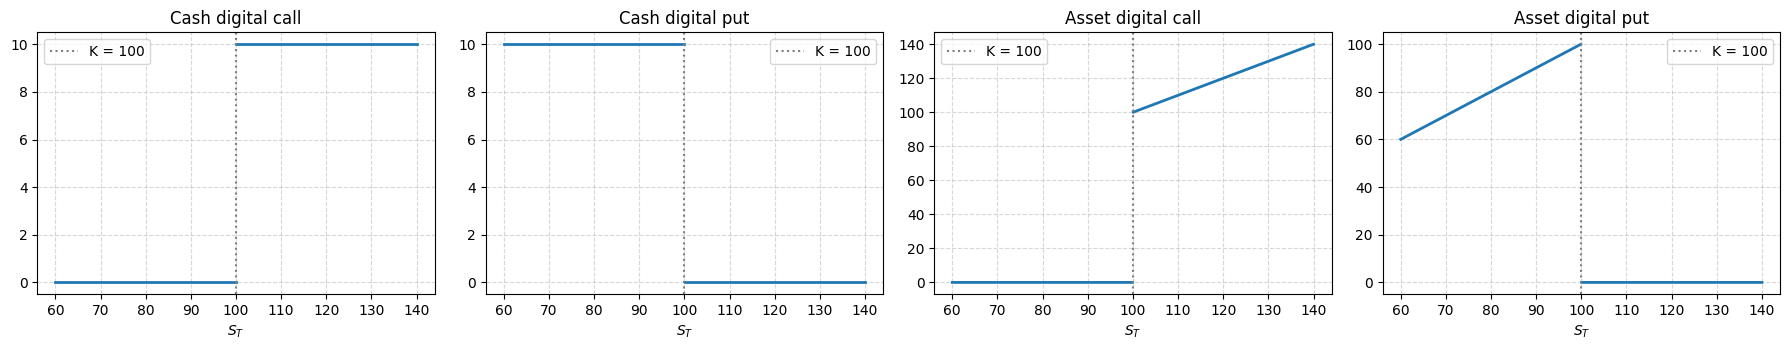

In [2]:
S = np.linspace(60, 140, 801)
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
specs = [("Cash digital call", digital_product(100, 1.0, True, cash=10)), ("Cash digital put", digital_product(100, 1.0, False, cash=10)),
         ("Asset digital call", digital_product(100, 1.0, True, asset=True)), ("Asset digital put", digital_product(100, 1.0, False, asset=True))]
for ax, (title, option) in zip(axes, specs):
    payoff = option.payoff(S).astype(float)
    payoff[np.abs(S - 100) < 0.05] = np.nan          # do not draw the vertical jump at the strike
    ax.plot(S, payoff, linewidth=2)
    ax.axvline(100, color="grey", linestyle=":", label="K = 100")
    ax.set_title(title)
    ax.set_xlabel("$S_T$")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend()
plt.tight_layout()
plt.show()

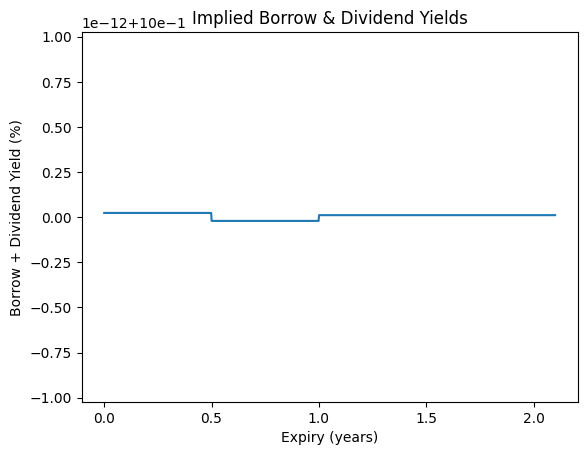

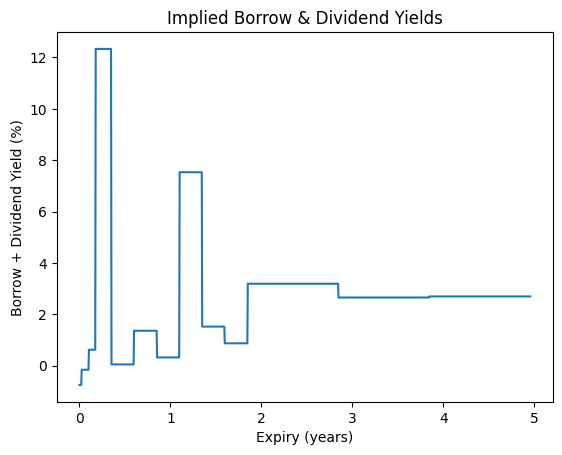

CAC40 2025-02-12 : S0 = 8042.19, 142 quotes on 13 expiries
Heston : v0=0.0197, theta=0.0438, kappa=1.3079, xi=0.4820, rho=-0.6050 | implied vol RMSE = 0.421 vol pts


In [3]:
flat = flat_market()
raw_flat = MonteCarloPricer(n_paths=100_000, steps_per_year=252, seed=1, control_variate=False)

mkt = cac40_heston()
heston, S0, T = mkt.heston, mkt.S0, 1.0
cash = 1000.0
pricer = MonteCarloPricer(n_paths=50_000, steps_per_year=252, seed=42)
raw = MonteCarloPricer(n_paths=50_000, steps_per_year=252, seed=42, control_variate=False)

# Part I : European digitals

The digital is paid at maturity only: $\text{price} = D(T)\,\mathbb{E}[\text{payoff}(S_T)]$.

## I.1 Validation in a flat Black-Scholes market

Closed forms: cash-or-nothing $= \text{cash}\, D(T) N(\pm d_2)$, asset-or-nothing $= D(T) F(T) N(\pm d_1)$
(`BlackScholes.bs_price_digital`). The pricer without control variate is compared with them; the
"semi-analytical" column is $-\partial C / \partial K$ computed from the model vanilla prices, which is also the
exact price used by the control variate.

In [4]:
rows = []
for K in [90, 100, 110]:
    for isCall in [True, False]:
        for asset in [False, True]:
            res = digital_pricer(flat.heston, K, 1.0, isCall, cash=10, asset=asset, pricer=raw_flat)
            exact = flat.bs_model.bs_price_digital(1.0, K, flat.sigma, isCall, cash=10, asset=asset)
            rows.append({"Option": f"{res['product'].code} K={K}", "Black": exact, "Semi-analytical": res["european"],
                         "Monte Carlo": res["price"], "Std error": res["stderr"],
                         "Error / std error": (res["price"] - exact) / res["stderr"]})
pd.DataFrame(rows).set_index("Option")

,Black,Semi-analytical,Monte Carlo,Std error,Error / std error
Option,,,,,
CashDigitalCall K=90,6.80122,6.80125,6.8002,0.0106372,-0.0954769
AssetDigitalCall K=90,75.8701,75.8698,75.8733,0.081581,0.0390319
CashDigitalPut K=90,2.90324,2.90321,2.90425,0.0106372,0.0954769
AssetDigitalPut K=90,23.1348,23.1352,23.1355,0.0857219,0.00747517
CashDigitalCall K=100,4.85223,4.85226,4.85232,0.000168087,0.577346
AssetDigitalCall K=100,57.3496,57.3493,57.3655,0.0330026,0.482112
CashDigitalPut K=100,4.85223,4.85219,4.85213,0.000168087,-0.577346
AssetDigitalPut K=100,41.6554,41.6557,41.6433,0.0212791,-0.567971
CashDigitalCall K=110,3.07477,3.07481,3.07515,0.0104546,0.0362228


## I.2 CAC40 under the calibrated Heston model

A digital is the derivative of the call price with respect to the strike, $-\partial C/\partial K$. With a smile,
$C(K) = C_{BS}(K, \sigma(K))$, so
$$
\text{Digital} = -\frac{\partial C_{BS}}{\partial K} - \mathcal{V}\,\frac{\partial \sigma}{\partial K}.
$$
With a negative skew ($\partial\sigma/\partial K < 0$), the digital call is worth **more** than the Black digital
computed with the implied volatility of its strike. The table compares the Heston price, the Monte Carlo price
and this Black digital.

In [5]:
rows = []
for K in [7200, 7600, 8000, 8400, 8800]:
    for isCall in [True, False]:
        res = digital_pricer(heston, K, T, isCall, cash=cash, pricer=raw)
        black = mkt.bs_model.bs_price_digital(T, K, float(mkt.iv_surface.get_vol(T, K)), isCall, cash=cash)
        rows.append({"Option": f"{'Call' if isCall else 'Put'} K={K}", "Heston (from Lewis)": res["european"],
                     "Monte Carlo": res["price"], "Std error": res["stderr"],
                     "Black, smile vol at K": black, "Skew effect": res["european"] - black})
pd.DataFrame(rows).set_index("Option")

,Heston (from Lewis),Monte Carlo,Std error,"Black, smile vol at K",Skew effect
Option,,,,,
Call K=7200,764.622,765.944,1.56323,687.264,77.358
Put K=7200,212.347,211.025,1.56323,289.705,-77.358
Call K=7600,677.236,676.727,1.63077,584.146,93.0898
Put K=7600,299.733,300.242,1.63077,392.823,-93.0898
Call K=8000,559.025,557.42,1.62664,466.373,92.6518
Put K=8000,417.945,419.55,1.62664,510.597,-92.6518
Call K=8400,411.867,410.562,1.61718,340.38,71.4868
Put K=8400,565.103,566.408,1.61718,636.589,-71.4868
Call K=8800,259.989,257.216,1.60849,225.963,34.026


## I.3 Digital barrier options

Cash digital calls and puts (cash = 1000, K = 8000) with a down barrier at 7200 or an up barrier at 8800.
In / Out parity: knock-in + knock-out = digital. Continuous monitoring (Brownian bridge) against daily discrete
monitoring.

In [6]:
rows = []
for isCall in [True, False]:
    for direction, H in [("down", 7200.0), ("up", 8800.0)]:
        prices = {}
        for knock in ["in", "out"]:
            barrier = dict(barrier=H, direction=direction, knock=knock)
            res = digital_pricer(heston, 8000, T, isCall, cash=cash, pricer=pricer, **barrier)
            discrete = digital_pricer(heston, 8000, T, isCall, cash=cash, pricer=pricer, monitoring="discrete", **barrier)
            prices[knock] = res["price"]
            rows.append({"Option": res["product"].code, "H": H, "Price": res["price"], "Std error": res["stderr"],
                         "Price (discrete)": discrete["price"]})
        rows.append({"Option": f"in + out vs digital {'call' if isCall else 'put'}", "H": H,
                     "Price": prices["in"] + prices["out"], "Std error": np.nan, "Price (discrete)": res["european"]})
pd.DataFrame(rows).set_index("Option")

,H,Price,Std error,Price (discrete)
Option,,,,
CDI-CashDigital,7200,113.374,1.23823,97.7431
CDO-CashDigital,7200,445.651,1.23824,461.281
in + out vs digital call,7200,559.025,NaN,559.025
CUI-CashDigital,8800,377.383,1.44614,365.204
CUO-CashDigital,8800,181.641,1.44613,193.821
in + out vs digital call,8800,559.025,NaN,559.025
PDI-CashDigital,7200,350.936,1.00523,340.651
PDO-CashDigital,7200,67.0091,1.00523,77.2941
in + out vs digital put,7200,417.945,NaN,417.945


# Part II : Bermudan digitals

The holder can exercise on a set of dates $t_1 < \dots < t_n = T$ and receives the payoff at the exercise date.
The pricer uses Longstaff-Schwartz (regression of the continuation value on the in-the-money paths).

For a **cash** digital with non-negative rates the optimal rule is known: the exercise value is the constant
`cash`, while the continuation value is at most the discounted cash, so the option is exercised on the first
exercise date where it is in the money:
$$
\text{Bermudan} = \text{cash}\;\mathbb{E}\big[D(\tau)\,\mathbf 1_{\tau \le T}\big],\qquad
\tau = \min\{t_i : S_{t_i} > K\} \text{ (call)}.
$$
This rule is evaluated directly on the simulated paths and must match Longstaff-Schwartz.

## II.1 Validation in a flat Black-Scholes market (monthly exercise)

In [7]:
def first_itm_price(pricer, model, option):
    # Cash digital exercised on the first exercise date in the money, valued on the pricer's paths
    S, _ = pricer.paths(model, option.maturity)
    M = S.shape[0] - 1
    df = pricer.discount_factors(model, option.maturity, M)
    idx = option.exercise.indices(option.maturity, M)
    itm = option.payoff(S[idx]) > 0                                    # shape (n_dates, n_paths)
    exercised = itm.any(axis=0)
    first = idx[np.argmax(itm, axis=0)]
    samples = np.where(exercised, option.cash * df[first], 0.0)
    if pricer.antithetic:
        half = len(samples) // 2
        samples = 0.5 * (samples[:half] + samples[half:])
    return samples.mean(), samples.std(ddof=1) / np.sqrt(len(samples))

monthly = dict(exercise="bermudan", exercise_period=1 / 12)
rows = []
for K in [90, 100, 110]:
    for isCall in [True, False]:
        res = digital_pricer(flat.heston, K, 1.0, isCall, cash=10, pricer=raw_flat, **monthly)
        rule, rule_se = first_itm_price(raw_flat, flat.heston, res["product"])
        rows.append({"Option": f"{'Call' if isCall else 'Put'} K={K}", "European (semi-analytical)": res["european"],
                     "Bermudan LSM": res["price"], "Std error": res["stderr"],
                     "First date ITM": rule, "LSM - rule": res["price"] - rule})
pd.DataFrame(rows).set_index("Option")

,European (semi-analytical),Bermudan LSM,Std error,First date ITM,LSM - rule
Option,,,,,
Call K=90,6.80125,9.88898,0.00287316,9.88938,-0.000391334
Put K=90,2.90321,4.86381,0.00910729,4.86385,-3.97195e-05
Call K=100,4.85226,8.34545,0.0103332,8.34553,-7.62727e-05
Put K=100,4.85219,8.3457,0.0103327,8.34573,-2.9619e-05
Call K=110,3.07481,5.17529,0.00902041,5.17533,-3.99492e-05
Put K=110,6.62964,9.84602,0.00350482,9.84611,-8.23286e-05


## II.2 Number of exercise dates

From one exercise date (European) to one per simulation step (American): the Bermudan price increases with the
number of exercise dates and converges to the American price.

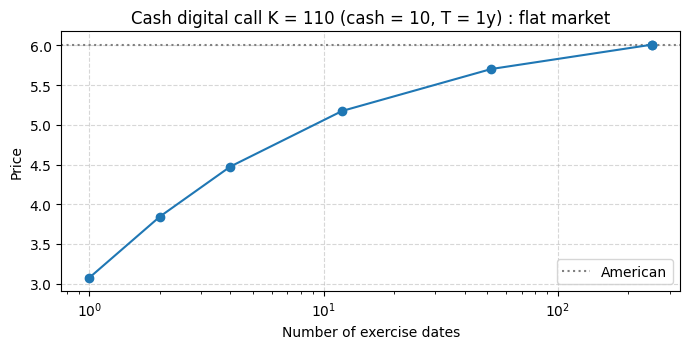

,Dates,Price,Std error
Exercise,,,
European,1,3.07515,0.0104546
Semi-annual,2,3.84473,0.00997119
Quarterly,4,4.47515,0.00935251
Monthly,12,5.17529,0.00902041
Weekly,52,5.70379,0.0092311
Daily,252,6.01026,0.0095964
American,252,6.01026,0.0095964


In [8]:
K = 110
frequencies = {"European": None, "Semi-annual": 1 / 2, "Quarterly": 1 / 4, "Monthly": 1 / 12,
               "Weekly": 1 / 52, "Daily": 1 / 252}
rows = []
for name, period in frequencies.items():
    style = dict() if period is None else dict(exercise="bermudan", exercise_period=period)
    res = digital_pricer(flat.heston, K, 1.0, True, cash=10, pricer=raw_flat, **style)
    rows.append({"Exercise": name, "Dates": len(res["product"].exercise.indices(1.0, raw_flat.n_steps(1.0))),
                 "Price": res["price"], "Std error": res["stderr"]})
american = digital_pricer(flat.heston, K, 1.0, True, cash=10, exercise="american", pricer=raw_flat)
rows.append({"Exercise": "American", "Dates": raw_flat.n_steps(1.0), "Price": american["price"], "Std error": american["stderr"]})
by_frequency = pd.DataFrame(rows).set_index("Exercise")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.errorbar(by_frequency["Dates"], by_frequency["Price"], yerr=2 * by_frequency["Std error"], marker="o", capsize=3)
ax.axhline(american["price"], color="grey", linestyle=":", label="American")
ax.set_xscale("log")
ax.set_xlabel("Number of exercise dates")
ax.set_ylabel("Price")
ax.set_title(f"Cash digital call K = {K} (cash = 10, T = 1y) : flat market")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()
by_frequency

## II.3 CAC40 under the calibrated Heston model (monthly exercise)

Without control variate, so that Longstaff-Schwartz and the exercise rule are computed on the same samples.

In [9]:
monthly = dict(exercise="bermudan", exercise_period=1 / 12)
rows = []
for K in [7200, 7600, 8000, 8400, 8800]:
    for isCall in [True, False]:
        res = digital_pricer(heston, K, T, isCall, cash=cash, pricer=raw, **monthly)
        rule, rule_se = first_itm_price(raw, heston, res["product"])
        rows.append({"Option": f"{'Call' if isCall else 'Put'} K={K}", "European": res["european"],
                     "Bermudan LSM": res["price"], "Std error": res["stderr"], "First date ITM": rule})
bermudan_cac = pd.DataFrame(rows).set_index("Option")
bermudan_cac["Early exercise premium"] = bermudan_cac["Bermudan LSM"] - bermudan_cac["European"]
bermudan_cac

,European,Bermudan LSM,Std error,First date ITM,Early exercise premium
Option,,,,,
Call K=7200,764.622,993.578,0.28453,993.627,228.956
Put K=7200,212.347,364.767,1.72231,364.801,152.42
Call K=7600,677.236,969.84,0.717696,970.16,292.603
Put K=7600,299.733,538.294,1.69478,538.313,238.561
Call K=8000,559.025,874.391,1.35024,874.496,315.366
Put K=8000,417.945,772.351,1.57605,772.459,354.406
Call K=8400,411.867,632.555,1.59856,632.573,220.689
Put K=8400,565.103,961.321,0.809627,961.746,396.219
Call K=8800,259.989,368.802,1.67147,368.876,108.813


# Part III : American digitals

With continuous exercise, the cash digital is exercised as soon as the spot reaches the strike: the American
cash digital call (put) is a **one-touch** on an up (down) barrier $H = K$, paid at hit. Black-Scholes closed form
(Reiner & Rubinstein), with $\mu = (r - q - \sigma^2/2)/\sigma^2$, $\lambda = \sqrt{\mu^2 + 2r/\sigma^2}$,
$z = \ln(H/S_0)/(\sigma\sqrt T) + \lambda\sigma\sqrt T$ and $\eta = -1$ (up) or $+1$ (down):
$$
\text{OneTouch} = \text{cash}\Big[(H/S_0)^{\mu+\lambda} N(\eta z) + (H/S_0)^{\mu-\lambda} N(\eta z - 2\eta\lambda\sigma\sqrt T)\Big].
$$
The Monte Carlo "American" option can only be exercised on the simulation dates (daily): it is a one-touch with
discrete monitoring, whose price is approximated by the continuous formula with the barrier shifted away from the
spot, $H\,e^{\pm 0.5826\,\sigma\sqrt{\Delta t}}$ (Broadie, Glasserman & Kou 1997).

## III.1 Validation in a flat Black-Scholes market

In [10]:
def one_touch(S0, H, T, r, q, sigma, cash, up):
    mu = (r - q - 0.5 * sigma**2) / sigma**2
    lam = np.sqrt(mu**2 + 2 * r / sigma**2)
    sT = sigma * np.sqrt(T)
    z = np.log(H / S0) / sT + lam * sT
    eta = -1.0 if up else 1.0
    return cash * ((H / S0)**(mu + lam) * norm.cdf(eta * z) + (H / S0)**(mu - lam) * norm.cdf(eta * z - 2 * eta * lam * sT))

shift = 0.5826 * flat.sigma * np.sqrt(1 / raw_flat.steps_per_year)
rows = []
for K, isCall in [(105, True), (110, True), (120, True), (95, False), (90, False), (80, False)]:
    res = digital_pricer(flat.heston, K, 1.0, isCall, cash=10, exercise="american", pricer=raw_flat)
    H_discrete = K * np.exp(shift if isCall else -shift)
    discrete = one_touch(flat.S0, H_discrete, 1.0, flat.r, flat.q, flat.sigma, 10, up=isCall)
    rows.append({"Option": f"{'Call' if isCall else 'Put'} K={K}",
                 "One-touch (continuous)": one_touch(flat.S0, K, 1.0, flat.r, flat.q, flat.sigma, 10, up=isCall),
                 "One-touch (daily, BGK)": discrete, "American LSM": res["price"], "Std error": res["stderr"],
                 "Error / std error": (res["price"] - discrete) / res["stderr"]})
pd.DataFrame(rows).set_index("Option")

,One-touch (continuous),"One-touch (daily, BGK)",American LSM,Std error,Error / std error
Option,,,,,
Call K=105,8.03069,7.74391,7.74578,0.010971,0.170994
Call K=110,6.27861,6.01855,6.01026,0.0095964,-0.863551
Call K=120,3.56647,3.37795,3.38351,0.0106366,0.52198
Put K=95,7.93252,7.64688,7.65021,0.0110067,0.302448
Put K=90,5.92382,5.67091,5.66175,0.00923557,-0.991783
Put K=80,2.60134,2.44918,2.44631,0.0110317,-0.260136


Strikes on the money side of the spot are excluded: the option is then immediately in the money and worth
`cash` with continuous exercise (exercise at $t = 0$ is not allowed by the pricer).

## III.2 CAC40 under the calibrated Heston model : European, Bermudan and American

Cash digitals (cash = 1000, T = 1y). Ordering European $\le$ Bermudan $\le$ American $\le$ cash, and the
American price divided by the cash is the (discounted) probability of touching the strike before maturity.

43.5s


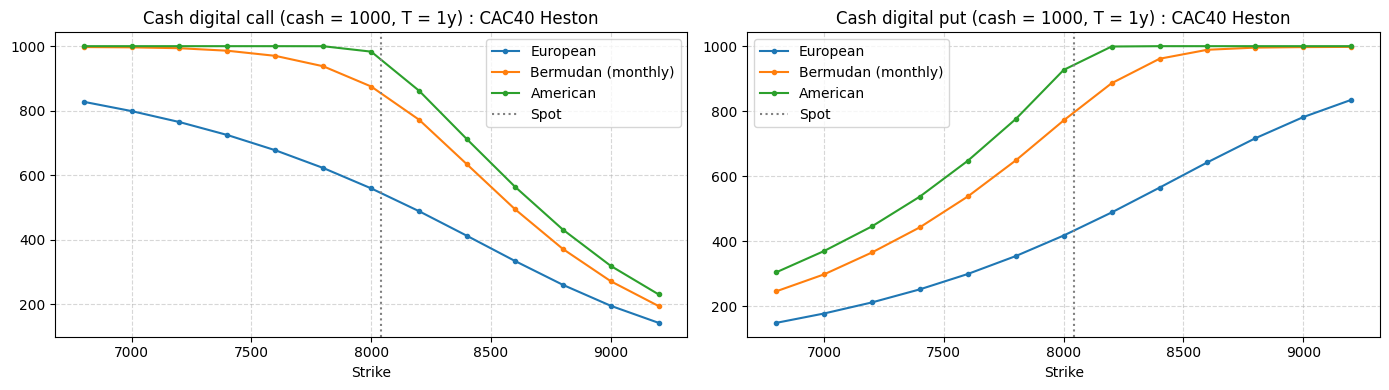

European  Bermudan (monthly)  American
Type K                                           
Call 6800   827.543             997.126   999.894
     7000   798.695             996.209   999.894
     7200   764.622             993.553   999.894
     7400    724.44             985.761   999.894
     7600   677.236             969.886   999.894
     7800   622.219             937.554   999.739
     8000   559.025             874.855   982.942
     8200   488.209             771.778   861.665
     8400   411.867              633.38   711.204
     8600   333.998             494.567   564.225
     8800   259.989             371.178   431.238
     9000   194.983             271.101   318.606
     9200   142.047             194.013   230.143
Put  6800   149.427             246.316   304.717
     7000   178.275             298.466   370.202
     7200   212.347             365.842   446.112
     7400   252.529             443.217   537.603
     7600   299.733             537.954   647.675
     7800    354.75              648.73   775.878
     8000   417.945             771.714   926.894
     8200   488.761             885.957   998.841
     8400   565.103             961.209   999.889
     8600   642.972             988.863   999.894
     8800    716.98             995.475   999.894
     9000   781.986             997.008   999.894
     9200   834.922             997.679   999.894

In [11]:
strikes = np.arange(6800.0, 9201.0, 200.0)
styles = {"European": dict(), "Bermudan (monthly)": dict(exercise="bermudan", exercise_period=1 / 12),
          "American": dict(exercise="american")}
start = time.time()
rows = []
for isCall in [True, False]:
    for K in strikes:
        row = {"Type": "Call" if isCall else "Put", "K": K}
        for name, style in styles.items():
            row[name] = digital_pricer(heston, K, T, isCall, cash=cash, pricer=pricer, **style)["price"]
        rows.append(row)
print(f"{time.time() - start:.1f}s")
styles_cac = pd.DataFrame(rows).set_index(["Type", "K"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, kind in zip(axes, ["Call", "Put"]):
    for name in styles:
        ax.plot(strikes, styles_cac.loc[kind, name], marker="o", markersize=3, label=name)
    ax.axvline(S0, color="grey", linestyle=":", label="Spot")
    ax.set_title(f"Cash digital {kind.lower()} (cash = 1000, T = 1y) : CAC40 Heston")
    ax.set_xlabel("Strike")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend()
plt.tight_layout()
plt.show()
styles_cac

# Part IV : Structuring

In a structured product the digital is usually paid as a **coupon** (in % of notional), financed by a budget
(the premium available, in % of notional). The price of a cash digital is linear in its cash, so
$$
\text{coupon} = \frac{\text{budget}}{\text{price of the digital paying } 1},
$$
which is what `digital_coupon` computes (one pricing per product). Strikes and barriers are in % of spot.

## IV.1 Coupon paid for a 5 % budget (CAC40, T = 1y)

In [12]:
budget = 5.0                                                     # % of notional
variants = {"European": dict(), "Bermudan (quarterly)": dict(exercise="bermudan", exercise_period=1 / 4),
            "American": dict(exercise="american"),
            "Down-and-out 80 %": dict(barrier=0.8 * S0, direction="down", knock="out")}
start = time.time()
rows = []
for isCall in [True, False]:
    for strike_pct in [90, 95, 100, 105, 110]:
        row = {"Type": "Call" if isCall else "Put", "Strike (% spot)": strike_pct}
        for name, kwargs in variants.items():
            row[name] = digital_coupon(heston, budget, strike_pct / 100 * S0, T, isCall=isCall, pricer=pricer, **kwargs)[0]
        rows.append(row)
print(f"{time.time() - start:.1f}s")
coupons = pd.DataFrame(rows).set_index(["Type", "Strike (% spot)"])
coupons

21.5s


European  Bermudan (quarterly)  American  \
Type Strike (% spot)                                             
Call 90                6.60074               5.29704   5.00053   
     95                7.49786               5.65757   5.00053   
     100               9.17975               6.60266   5.17579   
     105               12.6719               9.36778   7.37368   
     110               20.4963               16.2761   12.4068   
Put  90                22.7813               15.6523   10.8113   
     95                16.1232               10.6944    7.4486   
     100               11.5662               7.43501   5.22611   
     105               8.58525               5.67538   5.00053   
     110               6.82107               5.16442   5.00053   

                      Down-and-out 80 %  
Type Strike (% spot)                     
Call 90                         7.11092  
     95                         7.89831  
     100                        9.52263  
     105                        13.0444  
     110                        21.0311  
Put  90                         109.104  
     95                         42.5564  
     100                        22.1197  
     105                        13.6104  
     110                         9.7434

The coupon goes down when the digital is more likely to pay: in the money strikes and early exercise. The
American coupon is bounded below by the budget (the American digital is worth at most the cash, when it is
exercised at once). The knock-out barrier makes the digital cheaper, hence a higher coupon.

## IV.2 Command line

The same pricing from a terminal, with any inputs (`python digital.py --help` for the full list):
```bash
python digital.py --strike 100 --barrier 90 --budget 5
python digital.py --put --strike 95 --maturity 2 --exercise bermudan --period 0.5 --cash 8
python digital.py --market flat --spot 100 --rate 0.03 --div 0.01 --vol 0.2 --strike 110 --exercise american
```
`digital_cli` runs it from the notebook (`--no-calibrate` reuses the known Heston parameters).

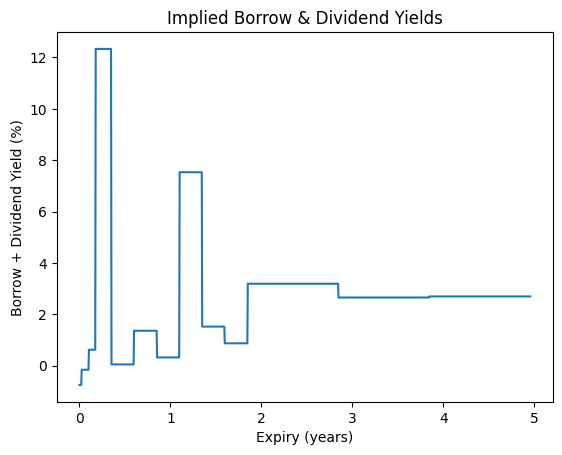

CAC40 2025-02-12 : S0 = 8042.19, 142 quotes on 13 expiries
Heston : v0=0.0197, theta=0.0438, kappa=1.3080, xi=0.4820, rho=-0.6050 | implied vol RMSE = 0.421 vol pts



CDO-CashDigital(K=8042.19, H=7237.97, T=1.0000, pays 100, continuous)   (S0 = 8042.19, cac40 market)
Price             : 42.7920 % of notional  (std error 0.1249)
European digital  : 54.4676 %   ->  Barrier effect : -11.6756 %


Budget 5 %       : digital coupon = 11.6844 % of notional (price of the digital paying 1 : 0.427920)


In [13]:
digital_cli(["--no-calibrate", "--strike", "100", "--barrier", "90", "--budget", "5"]);